# Phishing verisi — Keşifsel veri analizi

İlk çalışma: kaynak, yapı, kalite, tekrarlar ve değerlendirme ayrımı.
Her kontrolde soru, yöntem, bulgu, yorum/sınırlılık ve karar birlikte kaydedilir.
Ham veri değiştirilmez. Bu aşamada model eğitilmez, özellik seçilmez.

**Önceki çalışmaların sınırı:** Bu veri kümesinin tamamında daha önce analiz ve model sonuçları görülmüştü. Yeni ayrım gelecekteki kararları düzenler; aynı veriyi geriye dönük hiç görülmemiş bir dış test haline getirmez. Güçlü bağımsız değerlendirme için yeni bir dış/zamansal veri kümesi gerekir.

## 1. Amaç ve kullanım senaryosu

**Soru:** Hangi veriyle neyi anlayacağız?

Bu aşamanın amacı veri kalitesini ve yapısını anlamak, daha sonra uygulanacak hazırlık kararlarını gerekçelendirmektir. Canlı sistemin yalnızca URL mi yoksa sayfa içeriği de mi kullanacağı henüz kesinleştirilmedi. Bu nedenle mevcut sütunlar korunur; canlıda üretilemeyen özellikler seçilmiş kabul edilmez. Kaynak etiketler: 0 phishing, 1 meşru. Bu notebook şimdilik kaynak etiketlerini kullanır.

## 2. Kaynak ve tekrar üretilebilirlik

[PhiUSIIL — UCI](https://archive.ics.uci.edu/dataset/967/phiusiil%2Bphishing%2Burl%2Bdataset), Arvind Prasad ve Shalini Chandra (2024), CC BY 4.0. UCI 235.795 kayıt ve 54 özellik bildirir; CSV ayrıca dosya kimliği ve etiketi içerir. URL ve sayfa kaynak kodundan üretilmiş özellikler vardır. Her özellik için kesin çıkarım formülü, kayıt başına tarih ve kampanya bilgisi bu çalışmada doğrulanmış değildir.

**Kontrol:** Dosyanın SHA-256 özeti ve çalışma ortamı kaydedilir. Ağ isteği yapılmaz.

In [1]:
from pathlib import Path
import hashlib, json, platform, importlib.metadata
from itertools import combinations
from urllib.parse import urlsplit
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data/raw/PhiUSIIL_Phishing_URL_Dataset.csv').is_file())
SOURCE = ROOT/'data/raw/PhiUSIIL_Phishing_URL_Dataset.csv'
OUT = ROOT/'reports/initial_audit'
OUT.mkdir(parents=True, exist_ok=True)
SPLITS = ROOT/'data/processed'
SEED = 42
fingerprint = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
raw = pd.read_csv(SOURCE)
environment = {'python': platform.python_version(), **{p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn']}}
print('SHA-256:', fingerprint)
display(pd.Series(environment, name='Sürüm').to_frame())

SHA-256: a236549cd369cd80bd478ff8e1779cbf44c58d5c3f79f7a51a1adbed7d06d1c6


,Sürüm
python,3.12.10
numpy,2.4.4
pandas,3.0.2
scikit-learn,1.8.0


## 3. Veri yapısı

**Soru:** Bir satır neyi temsil ediyor, hangi alanlar var?
Bir satır kayıtlı bir URL/sayfa gözlemidir; aynı URL'nin birden fazla satırı olabilir.
Tip, eksik sayısı ve benzersiz değer sayısı envanterlenir. Bu tablo kesin özellik sözlüğü değildir; sütun adından formül uydurulmaz. Ham URL ve başlıklar raporda bağlantı olarak gösterilmez.

**Sütun sözlüğü:** `role` geçici kullanım notudur; tanımın doğrulandığı anlamına gelmez. Kaynaklar ve belirsizlikler [sütun sözlüğünde](../docs/data_dictionary.md) açıklanır.

In [2]:
schema = pd.DataFrame({'dtype':raw.dtypes.astype(str), 'missing':raw.isna().sum(), 'unique':raw.nunique(dropna=False)})
schema['role'] = ['target' if c=='label' else 'identifier/text/group candidate' if c in ['URL','Domain','FILENAME','Title','TLD'] else 'recorded feature; formula to verify' for c in schema.index]
schema.to_csv(OUT/'schema.csv', index_label='column')
display(schema)
display(pd.Series({'rows':len(raw), 'columns':len(raw.columns), 'numeric_columns':len(raw.select_dtypes(include='number').columns), 'text_columns':len(raw.select_dtypes(exclude='number').columns)}, name='Yapı').to_frame())
assert raw.columns.is_unique
assert raw.label.notna().all() and raw.label.isin([0,1]).all()

,dtype,missing,unique,role
FILENAME,str,0,235795,identifier/text/group candidate
URL,str,0,235370,identifier/text/group candidate
URLLength,int64,0,482,recorded feature; formula to verify
Domain,str,0,220086,identifier/text/group candidate
DomainLength,int64,0,101,recorded feature; formula to verify
IsDomainIP,int64,0,2,recorded feature; formula to verify
TLD,str,0,695,identifier/text/group candidate
URLSimilarityIndex,float64,0,36360,recorded feature; formula to verify
CharContinuationRate,float64,0,898,recorded feature; formula to verify
TLDLegitimateProb,float64,0,465,recorded feature; formula to verify


,Yapı
rows,235795
columns,56
numeric_columns,51
text_columns,5


### 3.1. Sütun açıklamaları ve doğrulanma durumu

**U-doğrudan:** UCI açıklaması. **Kod bulundu:** Yazarın uygulaması incelendi, yerel CSV uyumu henüz sınanmadı. **Yorum:** Sütun adından çalışma açıklaması; kesin formül doğrulanmadı.

Kaynaklar: [UCI](https://archive.ics.uci.edu/dataset/967/phiusiil%2Bphishing%2Burl%2Bdataset), [karakter oranı kodu](https://github.com/arvindbitm/PhiUSIIL/blob/main/CharConRate.ipynb), [başlık skoru kodu](https://github.com/arvindbitm/PhiUSIIL/blob/main/WebPageTitleMatchScore.ipynb).

| Sütun | Türkçe çalışma açıklaması | Grup / kullanım amacı | Durum | Kaynak |
|---|---|---|---|---|
| FILENAME | Kaynak dosya kimliği; UCI göz ardı edilebileceğini belirtir. | İzlenebilirlik; model girdisi değil | U-doğrudan | U |
| URL | Kaydedilmiş web adresi. | Ham metin, tekrar kontrolü ve host çıkarımı | Yorum | Sütun adı |
| URLLength | Kaydedilmiş URL uzunluğu; hangi gösterimin sayıldığı doğrulanmalı. | URL / uzunluk | Yorum | Sütun adı |
| Domain | Kaydedilmiş domain veya host metni. | Domain / gruplama adayı; registered-domain olduğu varsayılmaz | Yorum | Sütun adı |
| DomainLength | Kaydedilmiş domain uzunluğu. | Domain / uzunluk | Yorum | Sütun adı |
| IsDomainIP | Domain yerine IP adresi kullanımı göstergesi. | URL-domain / gösterge | Yorum | Sütun adı |
| TLD | Kaydedilmiş üst seviye alan adı uzantısı. | Kategorik özellik adayı | Yorum | Sütun adı |
| URLSimilarityIndex | URL benzerlik skoru; referans kümesi ve algoritma ayrıca doğrulanmalı. | Referans tabanlı skor / köken incelemesi | Yorum | Sütun adı |
| CharContinuationRate | Karakter türlerine göre en uzun kesintisiz dizileri kullanan oran. | Türetilmiş karakter özelliği | Kod bulundu | C |
| TLDLegitimateProb | Uzantıyla ilişkili meşruluk olasılığı olarak yorumlanan değer; hangi evrenden hesaplandığı belirsiz. | Referans tabanlı istatistik / sızıntı incelemesi | Yorum | Sütun adı |
| URLCharProb | URL karakterleriyle ilişkili olasılık skoru; referans dağılımı ve formülü doğrulanmalı. | Referans tabanlı karakter istatistiği | Yorum | Sütun adı |
| TLDLength | Kaydedilmiş uzantı uzunluğu. | Domain / uzunluk | Yorum | Sütun adı |
| NoOfSubDomain | Kaydedilmiş alt alan adı sayısı; www ve çok parçalı uzantı kuralları doğrulanmalı. | Domain / sayım | Yorum | Sütun adı |
| HasObfuscation | URL gizleme veya kodlama tekniği algılanması göstergesi. | URL / gösterge | Yorum | Sütun adı |
| NoOfObfuscatedChar | Gizlenmiş/kodlanmış kabul edilen karakter sayısı; algılama kuralı belirsiz. | URL / sayım | Yorum | Sütun adı |
| ObfuscationRatio | Gizlenmiş/kodlanmış karakter oranı; payda doğrulanmalı. | URL / oran | Yorum | Sütun adı |
| NoOfLettersInURL | URL'deki harf sayısı; sayılan URL parçası ve karakter kümesi doğrulanmalı. | URL / sayım | Yorum | Sütun adı |
| LetterRatioInURL | Harf oranı; kullanılan payda doğrulanmalı. | URL / oran | Yorum | Sütun adı |
| NoOfDegitsInURL | URL'deki rakam sayısı; özgün yazım korunmuştur. | URL / sayım | Yorum | Sütun adı |
| DegitRatioInURL | Rakam oranı; payda doğrulanmalı, özgün yazım korunmuştur. | URL / oran | Yorum | Sütun adı |
| NoOfEqualsInURL | URL'deki eşittir işaretlerinin sayısı. | URL / sayım | Yorum | Sütun adı |
| NoOfQMarkInURL | URL'deki soru işaretlerinin sayısı. | URL / sayım | Yorum | Sütun adı |
| NoOfAmpersandInURL | URL'deki ampersand işaretlerinin sayısı. | URL / sayım | Yorum | Sütun adı |
| NoOfOtherSpecialCharsInURL | Diğer özel karakterlerin sayısı; karakter listesi doğrulanmalı. | URL / sayım | Yorum | Sütun adı |
| SpacialCharRatioInURL | Özel karakter oranı; karakter listesi ve payda doğrulanmalı. | URL / oran | Yorum | Sütun adı |
| IsHTTPS | HTTPS kullanım göstergesi olarak yorumlanır; sertifika geçerliliği değildir. | URL / gösterge | Yorum | Sütun adı |
| LineOfCode | Sayfanın kaynak kodundaki satır sayısı olarak yorumlanır. | Sayfa içeriği / sayım | Yorum | Sütun adı |
| LargestLineLength | Kaynak koddaki en uzun satırın uzunluğu olarak yorumlanır. | Sayfa içeriği / uzunluk | Yorum | Sütun adı |
| HasTitle | Sayfa başlığının bulunması göstergesi. | Sayfa içeriği / gösterge | Yorum | Sütun adı |
| Title | Kaydedilmiş sayfa başlık metni. | Ham metin / özellik adayı | Yorum | Sütun adı |
| DomainTitleMatchScore | Başlık parçalarının dönüştürülmüş domain metniyle eşleşme skoru. | Başlık-domain / türetilmiş skor | Kod bulundu | T |
| URLTitleMatchScore | Başlık parçalarının dönüştürülmüş URL metniyle eşleşme skoru. | Başlık-URL / türetilmiş skor | Kod bulundu | T |
| HasFavicon | Site simgesinin bulunması göstergesi. | Sayfa içeriği / gösterge | Yorum | Sütun adı |
| Robots | Robot yönergeleriyle ilişkili gösterge; robots.txt mi yoksa HTML metadata mı olduğu doğrulanmalı. | Sayfa / anlam ayrıntısı belirsiz | Yorum | Sütun adı |
| IsResponsive | Duyarlı sayfa tasarımı algılanması göstergesi; ölçüm kuralı belirsiz. | Sayfa davranışı / gösterge | Yorum | Sütun adı |
| NoOfURLRedirect | URL yönlendirme sayısı olarak yorumlanır; 0/1 gözlenmesi tek başına tanımı değiştirmez. | Yönlendirme / sayım adayı | Yorum | Sütun adı |
| NoOfSelfRedirect | Kendine yönlendirme sayısı olarak yorumlanır; kendine yönlendirme kuralı belirsiz. | Yönlendirme / sayım adayı | Yorum | Sütun adı |
| HasDescription | Sayfa açıklamasının bulunması göstergesi. | Sayfa içeriği / gösterge | Yorum | Sütun adı |
| NoOfPopup | Açılır pencere sayısı; statik veya çalıştırılarak algılama yöntemi belirsiz. | Sayfa / sayım | Yorum | Sütun adı |
| NoOfiFrame | iframe öğelerinin sayısı. | Sayfa içeriği / sayım | Yorum | Sütun adı |
| HasExternalFormSubmit | Harici hedefe veri gönderen form göstergesi; harici tanımı doğrulanmalı. | Form / gösterge | Yorum | Sütun adı |
| HasSocialNet | Sosyal ağ bağlantısı veya içeriği algılanması göstergesi; kapsam belirsiz. | Sayfa içeriği / gösterge | Yorum | Sütun adı |
| HasSubmitButton | Form gönderme düğmesi bulunması göstergesi. | Form / gösterge | Yorum | Sütun adı |
| HasHiddenFields | Gizli form alanı bulunması göstergesi. | Form / gösterge | Yorum | Sütun adı |
| HasPasswordField | Parola giriş alanı bulunması göstergesi. | Form / gösterge | Yorum | Sütun adı |
| Bank | Bankacılıkla ilişkili ifade göstergesi; aranılan metin alanı ve sözlük doğrulanmalı. | Anahtar kelime / gösterge | Yorum | Sütun adı |
| Pay | Ödemeyle ilişkili ifade göstergesi; eşleme kuralı doğrulanmalı. | Anahtar kelime / gösterge | Yorum | Sütun adı |
| Crypto | Kriptoyla ilişkili ifade göstergesi; eşleme kuralı doğrulanmalı. | Anahtar kelime / gösterge | Yorum | Sütun adı |
| HasCopyrightInfo | Telif hakkı bilgisi algılanması göstergesi. | Sayfa içeriği / gösterge | Yorum | Sütun adı |
| NoOfImage | Görsel sayısı; hangi öğelerin sayıldığı doğrulanmalı. | Sayfa kaynakları / sayım | Yorum | Sütun adı |
| NoOfCSS | CSS kaynağı sayısı; satır içi ve harici CSS kapsamı doğrulanmalı. | Sayfa kaynakları / sayım | Yorum | Sütun adı |
| NoOfJS | JavaScript kaynağı sayısı; satır içi ve harici script kapsamı doğrulanmalı. | Sayfa kaynakları / sayım | Yorum | Sütun adı |
| NoOfSelfRef | Aynı siteye yönelen referans sayısı; host veya registered-domain kuralı belirsiz. | Bağlantılar / sayım | Yorum | Sütun adı |
| NoOfEmptyRef | Boş kabul edilen referans sayısı; boş dize, # vb. kapsamı doğrulanmalı. | Bağlantılar / sayım | Yorum | Sütun adı |
| NoOfExternalRef | Harici referans sayısı; harici hedef kuralı doğrulanmalı. | Bağlantılar / sayım | Yorum | Sütun adı |
| label | Kaynak sınıf etiketi: 0 phishing, 1 meşru. | Hedef; model girdisi olamaz | U-doğrudan | U |


**Dikkat:** Yazarın karakter oranı örneği dönüştürülmüş domain üzerinde çalışır; tam URL ile eşdeğer sayılmaz. Başlık skoru önişlemesi ve sınırlılıkları sözlük dosyasında açıklanır.

## 4. Kalite ve bütünlük

**Soru:** Eksik/boş değer, yer tutucu, sonsuz sayı veya URL ayrıştırma sorunu var mı?
Yer tutucular yalnızca inceleme işaretidir; otomatik olarak eksik sayılmaz.
URL kontrolü şema/host/port yapısına bakar, sitenin varlığını veya güvenliğini kanıtlamaz. Negatif sayılar incelenmek üzere sayılır; her sütunda otomatik hata kabul edilmez.

In [3]:
quality = pd.DataFrame({'missing':raw.isna().sum(), 'blank':0, 'placeholder':0, 'infinite':0, 'negative':0})
for c in raw.select_dtypes(exclude='number'):
    s = raw[c].astype('string').str.strip()
    quality.loc[c,'blank'] = int(s.eq('').sum())
    quality.loc[c,'placeholder'] = int(s.str.lower().isin(['unknown','none','null','nan','n/a','-']).sum())
for c in raw.select_dtypes(include='number'):
    quality.loc[c,'infinite'] = int(np.isinf(raw[c].to_numpy()).sum())
    quality.loc[c,'negative'] = int(raw[c].lt(0).sum())
quality.to_csv(OUT/'quality.csv', index_label='column')
display(quality)
def inspect_url(value):
    if not isinstance(value,str) or not value.strip(): return 'missing_or_blank'
    if any(c.isspace() or ord(c)<32 for c in value): return 'whitespace_or_control'
    try:
        parts = urlsplit(value)
        port = parts.port
        if parts.scheme.lower() not in {'http','https'} or not parts.hostname: return 'scheme_or_host'
        if port == 0: return 'port_zero'
        return 'ok'
    except ValueError: return 'parse_error'
url_status = raw.URL.map(inspect_url)
display(url_status.value_counts().rename('rows').to_frame())
pd.DataFrame({'source_row':raw.index, 'status':url_status}).loc[lambda d:d.status.ne('ok')].to_csv(OUT/'url_issues.csv', index=False)
display(Markdown(f"**Bulgu:** Eksik hücre: {int(quality.missing.sum()):,}; boş metin: {int(quality.blank.sum()):,}; sonsuz sayı: {int(quality.infinite.sum()):,}; temel URL kontrolünde sorun: {int(url_status.ne('ok').sum()):,}. **Karar:** Bu aşamada doldurma, kırpma veya satır silme yapılmadı."))

,missing,blank,placeholder,infinite,negative
FILENAME,0,0,0,0,0
URL,0,0,0,0,0
URLLength,0,0,0,0,0
Domain,0,0,0,0,0
DomainLength,0,0,0,0,0
IsDomainIP,0,0,0,0,0
TLD,0,0,0,0,0
URLSimilarityIndex,0,0,0,0,0
CharContinuationRate,0,0,0,0,0
TLDLegitimateProb,0,0,0,0,0


,rows
URL,
ok,235795


**Bulgu:** Eksik hücre: 0; boş metin: 0; sonsuz sayı: 0; temel URL kontrolünde sorun: 0. **Karar:** Bu aşamada doldurma, kırpma veya satır silme yapılmadı.

## 5. Tekrarlar ve çelişkiler

**Soru:** Aynı satır mı tekrarlanmış, aynı URL için farklı ölçüm mü var?
Tam satır tekrarı, dosya kimliği dışındaki aynı içerik, URL tekrarı ve çelişkili etiket ayrı sayılır. Aynı URL'nin farklı özellikli kayıtlarını zaman bilgisi olmadan tek bir ölçüm olarak varsaymayız.

**Ayrım politikası:** Bu başlangıçta satır silinmez. Aynı URL'nin tüm gözlemleri aynı grupta tutulur. Tekrarların eğitimde ağırlık yaratması ayrıca değerlendirilecek; final veri henüz üretilmiyor.

### Neden henüz silmiyoruz?

425, ilk kayıttan sonraki ek gözlem sayısıdır; tekrar URL gruplarında toplam
850 kayıt vardır. Bu çiftler tamamen aynı değildir. Farkın zaman, yönlendirme,
URL normalizasyonu veya çıkarım hatasından kaynaklandığı henüz bilinmiyor.
İlk kaydı tutmak doğruluğunu kanıtlamaz. Tüm tekrar gruplarını çıkarmak ise
850 kaydı siler; tekil URL'lerden oluşan farklı bir örneklem üretir.

Koruma kararı geçicidir: tekrarlar bazı sitelerin eğitimdeki ağırlığını artırabilir.
Aynı URL/host'u aynı kümede tutmak kümeler arası örtüşmeyi önler, bu ağırlık
sorununu çözmez. İnceleme sonrası temsilci kayıt seçme, ağırlıklandırma veya
dışlama kararı gerekçelendirilmelidir. Ham dosya her durumda korunur.

**Örnek incelemesi:** Ayrım oluşturulduktan hemen sonraki **6.1** bölümünde,
yalnızca eğitim kümesinden tekrar URL çiftleri yan yana gösterilir.


In [4]:
repeated = raw.URL.duplicated(keep=False)
duplicate_records = raw.loc[repeated]
varying = duplicate_records.groupby('URL').nunique(dropna=False) if repeated.any() else pd.DataFrame()
conflicts = int(raw.groupby('URL').label.nunique().gt(1).sum())
feature_columns = [c for c in raw if c not in ['FILENAME','URL','label']]
different_measurements = int(varying[feature_columns].gt(1).any(axis=1).sum()) if len(varying) else 0
duplicate_summary = {'exact_duplicate_rows':int(raw.duplicated().sum()),
 'duplicate_rows_excluding_filename':int(raw.drop(columns='FILENAME').duplicated().sum()),
 'extra_url_records':int(raw.URL.duplicated().sum()),
 'rows_in_repeated_urls':int(repeated.sum()), 'conflicting_url_labels':conflicts,
 'repeated_urls_with_different_features':different_measurements}
display(pd.Series(duplicate_summary, name='Sayı').to_frame())
if len(varying):
    varying.gt(1).sum().rename('repeated_urls_with_variation').to_csv(OUT/'duplicate_variation.csv', index_label='column')
assert conflicts == 0, 'Aynı URL için çelişkili etiketler incelenmeli; ayrım durduruldu.'
display(Markdown(f"**Bulgu:** {duplicate_summary['extra_url_records']:,} ek URL kaydı var; {different_measurements:,} tekrar URL grubunda özellikler değişiyor. **Yorum:** URL tekrarı, tam satır tekrarıyla aynı değildir. **Karar:** Kayıtları şimdilik koru; tüm tekrar gözlemlerini aynı ayrımda tut."))

,Sayı
exact_duplicate_rows,0
duplicate_rows_excluding_filename,0
extra_url_records,425
rows_in_repeated_urls,850
conflicting_url_labels,0
repeated_urls_with_different_features,425


**Bulgu:** 425 ek URL kaydı var; 425 tekrar URL grubunda özellikler değişiyor. **Yorum:** URL tekrarı, tam satır tekrarıyla aynı değildir. **Karar:** Kayıtları şimdilik koru; tüm tekrar gözlemlerini aynı ayrımda tut.

## 6. Hedef dağılımı ve grup bazlı ayrım

**Soru:** Etiket oranları ve tekrarlanan hostlar nasıl? Aynı host/URL farklı kümelere sızmadan nasıl ayrılır?

Etiket oranını yalnızca genel kapsamı tanımak için gösteririz. Ayrım etiketlere göre en iyi görünen tohumu aramaz: sabit 42/43 tohumları kullanılır. URL'den ayrıştırılan hostname küçük harfe, IDNA biçimine çevrilir ve sondaki nokta kaldırılır. Aynı URL farklı kaynak domain alanlarıyla verilse bile URL hostname'i aynı gruptadır.

Yaklaşık 60/20/20 **host grubu** ayrılır; satır oranları tam eşit olmayabilir. Bu, kayıtlı domain metninden daha açık bir gruplama kuralıdır; kayıtlı domain ile uyuşmazlık sayısı ayrıca raporlanır. Kayıtlı zaman olmadığı için zamansal ayrım yapılmaz. [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) grup oranlarını esas alır.

**Sınır:** Aynı kayıtlı alan adının farklı alt alanları veya benzer sayfa şablonları farklı kümelerde olabilir. Registered-domain ve kampanya bağımsızlığı iddia edilmez.

In [5]:
assert url_status.eq('ok').all(), 'URL sorunları gruplama öncesi incelenmeli.'
def host_key(url):
    return urlsplit(url).hostname.rstrip('.').encode('idna').decode('ascii').lower()
groups = raw.URL.map(host_key)
recorded_domains = raw.Domain.astype('string').str.strip().str.lower().str.rstrip('.')
label_counts = raw.label.value_counts().sort_index().rename_axis('original_label').to_frame('rows')
label_counts['percent'] = label_counts.rows/len(raw)*100
display(label_counts)
group_audit = {'unique_url_hosts':int(groups.nunique()), 'max_rows_per_host':int(groups.value_counts().max()),
               'recorded_domain_host_mismatch_rows':int(groups.ne(recorded_domains).sum())}
display(pd.Series(group_audit, name='Grup kontrolü').to_frame())
outer = GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED)
dev_idx, test_idx = next(outer.split(raw,groups=groups))
inner = GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED+1)
train_rel, val_rel = next(inner.split(raw.iloc[dev_idx], groups=groups.iloc[dev_idx]))
indices = {'train':dev_idx[train_rel], 'validation':dev_idx[val_rel], 'test':test_idx}
manifest = pd.DataFrame({'source_row':raw.index, 'partition':''})
for name, idx in indices.items(): manifest.loc[idx,'partition'] = name
assert manifest.partition.ne('').all() and manifest.source_row.is_unique
for a,b in combinations(indices,2):
    assert not set(groups.iloc[indices[a]]) & set(groups.iloc[indices[b]])
    assert not set(raw.URL.iloc[indices[a]]) & set(raw.URL.iloc[indices[b]])
split_summary = pd.DataFrame([{'partition':name,'rows':len(idx),'host_groups':groups.iloc[idx].nunique(),'row_percent':len(idx)/len(raw)*100} for name,idx in indices.items()])
display(split_summary)
SPLITS.mkdir(exist_ok=True)
manifest_path = SPLITS/'split_manifest.csv'
lock_path = SPLITS/'split_metadata.json'
lock = {'source_sha256':fingerprint,'seed':SEED,'group_rule':'parsed_hostname_idna_lower_strip_trailing_dot_v1','policy':'retain_all_source_rows','sklearn':environment['scikit-learn']}
if manifest_path.exists() or lock_path.exists():
    assert manifest_path.exists() and lock_path.exists(), 'Eksik ayrım dosyaları incelenmeli.'
    assert json.loads(lock_path.read_text(encoding='utf-8')) == lock, 'Ayrım ayarları değişti; mevcut kilidi inceleyin.'
    pd.testing.assert_frame_equal(pd.read_csv(manifest_path),manifest)
else:
    manifest.to_csv(manifest_path,index=False)
    lock_path.write_text(json.dumps(lock,indent=2),encoding='utf-8')
split_summary.to_csv(OUT/'split_summary.csv',index=False)
audit = {'source_sha256':fingerprint,'rows':len(raw),'columns':len(raw.columns), 'quality_totals':{c:int(quality[c].sum()) for c in quality}, 'duplicates':duplicate_summary, 'groups':group_audit,'environment':environment}
(OUT/'audit_summary.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == fingerprint
# Ayrıntılı EDA için yalnızca eğitim verisi çalışma değişkeninde tutulur.
train = raw.iloc[indices['train']].copy()
del raw, duplicate_records, groups, recorded_domains
display(Markdown('**Karar:** Ayrım kaynak satır numaralarıyla kilitlendi. Ham dosya değişmedi; satır silinmedi. Doğrulama ve test için özellik dağılımları veya hedef ilişkileri incelenmedi. Sonraki bölümler yalnızca `train` ile ilerleyecek.'))

,rows,percent
original_label,,
0,100945,42.810492
1,134850,57.189508


,Grup kontrolü
unique_url_hosts,220077
max_rows_per_host,1197
recorded_domain_host_mismatch_rows,36


,partition,rows,host_groups,row_percent
0,train,141254,132045,59.905426
1,validation,46958,44016,19.914756
2,test,47583,44016,20.179817


**Karar:** Ayrım kaynak satır numaralarıyla kilitlendi. Ham dosya değişmedi; satır silinmedi. Doğrulama ve test için özellik dağılımları veya hedef ilişkileri incelenmedi. Sonraki bölümler yalnızca `train` ile ilerleyecek.

### 6.1. Tekrar URL kayıtlarını yan yana inceleme

Bu, 5. bölümdeki tekrar kontrolünün ayrıntılı devamıdır. Test kayıtlarını
incelememek için ayrımdan sonra yalnızca `train` üzerinde çalışır.

- `N_GROUPS`: Gösterilecek URL grubu sayısı; başlangıçta 3.
- `SHOW_URLS`: Varsayılan kapalı. Açılırsa ham URL metni gösterilir; bağlantılara gitmeyin ve hassas sorgu değerlerini paylaşmayın.
- `GROUP_OFFSET`: Sonraki grupları görmek için 3, 6 vb. yapabilirsiniz.

Her çiftte kaynak satır numarası ve dosya kimliği gösterilir. Sonraki tabloda
yalnızca değişen alanlar listelenir. Böylece 56 sütun arasında fark aramak gerekmez.
Son tablo, eğitim verisinde üç farklı tekrar politikasının kaç satır bırakacağını
hesaplar; hiçbir politikayı uygulamaz.


In [6]:
N_GROUPS = 3
GROUP_OFFSET = 0
SHOW_URLS = False

assert isinstance(N_GROUPS, int) and N_GROUPS > 0
assert isinstance(GROUP_OFFSET, int) and GROUP_OFFSET >= 0
train_repeats = train.loc[train['URL'].duplicated(keep=False)]
repeat_urls = train_repeats['URL'].drop_duplicates().iloc[GROUP_OFFSET:GROUP_OFFSET + N_GROUPS]
print(f'Eğitimde tekrar URL grubu: {train_repeats.URL.nunique():,}; bu gruplardaki kayıt: {len(train_repeats):,}')

for group_no, url in enumerate(repeat_urls, start=GROUP_OFFSET + 1):
    pair = train_repeats.loc[train_repeats['URL'].eq(url)].copy()
    changed = [c for c in pair.columns
               if c not in ['FILENAME', 'URL'] and pair[c].nunique(dropna=False) > 1]
    print(f'\nGrup {group_no} — {len(pair)} kayıt, {len(changed)} değişen alan')
    if SHOW_URLS:
        # repr prevents terminal control sequences from being interpreted.
        print('URL (metin):', repr(url))
    display(pair[['FILENAME', 'label']].rename_axis('source_row'))
    if changed:
        comparison = pair[changed].T
        comparison.columns = [f'source_row={i}' for i in pair.index]
        with pd.option_context('display.max_rows', None, 'display.max_columns', None):
            display(comparison.rename_axis('değişen_sütun'))
    else:
        print('FILENAME dışında değişen alan yok.')

policy_counts = pd.DataFrame([
    {'politika':'Tüm kayıtları koru (mevcut)', 'kalan_satır':len(train), 'çıkarılan_satır':0},
    {'politika':'Her URL için ilk kaydı tut (uygulanmadı)',
     'kalan_satır':int((~train.URL.duplicated()).sum()),
     'çıkarılan_satır':int(train.URL.duplicated().sum())},
    {'politika':'Tekrar eden URL gruplarını tamamen çıkar (uygulanmadı)',
     'kalan_satır':int((~train.URL.duplicated(keep=False)).sum()),
     'çıkarılan_satır':int(train.URL.duplicated(keep=False).sum())},
])
display(policy_counts)
print('Bu hücre train verisini veya ayrım manifestini değiştirmez.')


Eğitimde tekrar URL grubu: 253; bu gruplardaki kayıt: 506

Grup 1 — 2 kayıt, 6 değişen alan


,FILENAME,label
source_row,,
978,8028663.txt,0
136059,oph02824.txt,0


,source_row=978,source_row=136059
değişen_sütun,,
URLLength,52,53
URLCharProb,0.058589,0.058669
NoOfLettersInURL,38,39
LetterRatioInURL,0.731,0.736
SpacialCharRatioInURL,0.115,0.113
Title,etiliseramikwp-includesvectorloginht,etiliseramikwp-includesvectorloginhtm



Grup 2 — 2 kayıt, 5 değişen alan


,FILENAME,label
source_row,,
2543,oph02762.txt,0
46583,8028549.txt,0


,source_row=2543,source_row=46583
değişen_sütun,,
URLLength,54.000,53.000
LetterRatioInURL,0.481,0.491
DegitRatioInURL,0.278,0.283
NoOfOtherSpecialCharsInURL,5.000,4.000
SpacialCharRatioInURL,0.093,0.075



Grup 3 — 2 kayıt, 5 değişen alan


,FILENAME,label
source_row,,
2583,8028447.txt,0
126412,oph02790.txt,0


,source_row=2583,source_row=126412
değişen_sütun,,
URLLength,49.000,50.00
LetterRatioInURL,0.776,0.76
NoOfOtherSpecialCharsInURL,4.000,5.00
SpacialCharRatioInURL,0.082,0.10
LargestLineLength,58.000,59.00


,politika,kalan_satır,çıkarılan_satır
0,Tüm kayıtları koru (mevcut),141254,0
1,Her URL için ilk kaydı tut (uygulanmadı),141001,253
2,Tekrar eden URL gruplarını tamamen çıkar (uygu...,140748,506


Bu hücre train verisini veya ayrım manifestini değiştirmez.


### 6.2. Kayıtlı özellikler URL metniyle tutarlı mı?

**Soru:** Uzunluk, domain, HTTPS ve karakter sayıları eldeki URL metninden yeniden hesaplanabiliyor mu?

**Yöntem:** Yalnızca `train` üzerinde birden fazla açık hesaplama adayını karşılaştırırız.
Protokolün çıkarılması, sondaki slash, www, percent-decoding ve Unicode/IDNA gibi
ayrıntılar sonucu değiştirebilir. En yüksek uyumlu aday da orijinal formülün kanıtı değildir.
Kaynak URL, yönlendirme sonrası URL veya farklı toplama anı kullanılmış olabilir.
Kayıtlı değerler değiştirilmez; ağ bağlantısı kurulmaz, doğrulama/test okunmaz.

**Çıktılar:** Her aday için eşleşme ve fark oranı, URL uzunluk farklarının sıklığı,
domain farklarının türleri ve sınırlı örnekler. Örneklerde ham adresler varsayılan
gizlidir; incelemek için `SHOW_URL_TEXT = True` yapılabilir.


In [7]:
import re
from urllib.parse import unquote

SHOW_URL_TEXT = False
MAX_EXAMPLES = 5
CHECKS = ROOT/'reports/consistency_audit'
CHECKS.mkdir(parents=True, exist_ok=True)
parsed_train = train.URL.map(urlsplit)
urls = train.URL
host = parsed_train.map(lambda x:x.hostname or '')
netloc = parsed_train.map(lambda x:x.netloc)
without_scheme = urls.str.replace(r'(?i)^https?://', '', regex=True)
without_www = without_scheme.str.replace(r'(?i)^www\.', '', regex=True)
domain_text = train.Domain.astype('string')
def normalize_host(text):
    try:
        return str(text).strip().rstrip('.').encode('idna').decode('ascii').lower()
    except UnicodeError:
        return str(text).strip().rstrip('.').lower()
normalized_host = host.map(normalize_host)
normalized_domain = domain_text.map(normalize_host)
no_www_host = normalized_host.str.replace(r'^www\.', '', regex=True)
no_www_domain = normalized_domain.str.replace(r'^www\.', '', regex=True)

comparisons = {}
def check(feature, rule, calculated):
    calculated = pd.Series(calculated, index=train.index)
    key = (feature, rule)
    matches = train[feature].eq(calculated).fillna(False)
    comparisons[key] = (calculated, matches)
    return {'feature':feature, 'candidate_rule':rule, 'rows':len(train),
            'matches':int(matches.sum()), 'mismatches':int((~matches).sum()),
            'match_percent':float(matches.mean()*100)}
results = []
for rule, values in {
    'raw_url_characters':urls.str.len(),
    'raw_url_utf8_bytes':urls.map(lambda x:len(x.encode('utf-8'))),
    'raw_url_without_final_slash':urls.str.replace(r'/$', '', regex=True).str.len(),
    'without_scheme':without_scheme.str.len(),
    'without_scheme_or_www':without_www.str.len(),
    'without_scheme_trailing_slash':without_scheme.str.rstrip('/').str.len(),
    'percent_decoded_url':urls.map(unquote).str.len(),
}.items(): results.append(check('URLLength',rule,values))
for rule, values in {
    'recorded_domain_characters':domain_text.str.len(),
    'parsed_hostname_characters':host.str.len(),
    'parsed_netloc_characters':netloc.str.len(),
    'normalized_idna_hostname':normalized_host.str.len(),
    'hostname_without_www':no_www_host.str.len(),
}.items(): results.append(check('DomainLength',rule,values))
results.append(check('Domain','normalized_hostname',normalized_host))
# Override string comparison to compare like-normalized recorded and parsed hosts.
matches = normalized_domain.eq(normalized_host)
comparisons[('Domain','normalized_hostname')] = (normalized_host,matches)
results[-1].update(matches=int(matches.sum()),mismatches=int((~matches).sum()),match_percent=float(matches.mean()*100))
results.append(check('IsHTTPS','parsed_scheme_https',parsed_train.map(lambda x:int(x.scheme.lower()=='https'))))
for feature, char in [('NoOfEqualsInURL','='),('NoOfQMarkInURL','?'),('NoOfAmpersandInURL','&')]:
    results.append(check(feature,'raw_url_literal_count',urls.str.count(re.escape(char))))
    results.append(check(feature,'decoded_url_literal_count',urls.map(unquote).str.count(re.escape(char))))
summary = pd.DataFrame(results)
summary.to_csv(CHECKS/'candidate_rules.csv',index=False)
with pd.option_context('display.max_rows',None,'display.max_colwidth',60):
    display(summary.round({'match_percent':3}))

length_delta = train.URLLength - urls.str.len()
delta_counts = length_delta.value_counts().rename_axis('recorded_minus_raw_length').to_frame('rows')
delta_counts['percent'] = delta_counts.rows/len(train)*100
delta_counts.to_csv(CHECKS/'url_length_deltas.csv')
print('En sık URL uzunluğu farkları (kayıtlı - eldeki metin):')
display(delta_counts.head(15))

domain_mismatch = normalized_domain.ne(normalized_host)
www_only = domain_mismatch & no_www_domain.eq(no_www_host)
domain_categories = pd.Series('same_normalized_host',index=train.index)
domain_categories.loc[www_only] = 'www_prefix_difference'
domain_categories.loc[domain_mismatch & ~www_only] = 'other_difference_requires_review'
domain_counts = domain_categories.value_counts().rename_axis('category').to_frame('rows')
domain_counts.to_csv(CHECKS/'domain_categories.csv')
display(domain_counts)

print('Ham URL uzunluğu uyuşmayan örnekler:')
example_idx = length_delta.loc[length_delta.ne(0)].index[:MAX_EXAMPLES]
examples = train.loc[example_idx,['FILENAME','URLLength','DomainLength']].copy()
examples['actual_url_length'] = urls.loc[example_idx].str.len()
examples['length_delta'] = length_delta.loc[example_idx]
if SHOW_URL_TEXT:
    examples['URL_text'] = urls.loc[example_idx].map(repr)
display(examples.rename_axis('source_row'))
print('Domain uyuşmazlığı örnekleri:')
domain_idx = domain_categories.loc[domain_categories.ne('same_normalized_host')].index[:MAX_EXAMPLES]
domain_examples = pd.DataFrame({'category':domain_categories.loc[domain_idx],
    'recorded_domain_length':domain_text.loc[domain_idx].str.len(),
    'parsed_hostname_length':host.loc[domain_idx].str.len()})
if SHOW_URL_TEXT:
    domain_examples['recorded_domain'] = domain_text.loc[domain_idx].map(repr)
    domain_examples['parsed_hostname'] = host.loc[domain_idx].map(repr)
display(domain_examples.rename_axis('source_row'))

repeat_idx = train.loc[train.URL.duplicated(keep=False)].index
repeat_length = pd.DataFrame({'recorded':train.loc[repeat_idx,'URLLength'],
    'actual':urls.loc[repeat_idx].str.len(), 'delta':length_delta.loc[repeat_idx]})
repeat_length.groupby('delta').size().rename('rows').to_csv(CHECKS/'repeated_url_length_deltas.csv')
overview = {
    'training_rows':len(train),
    'raw_url_length_mismatches':int(length_delta.ne(0).sum()),
    'normalized_domain_mismatches':int(domain_mismatch.sum()),
    'www_only_domain_mismatches':int(www_only.sum()),
    'https_mismatches':int((~comparisons[('IsHTTPS','parsed_scheme_https')][1]).sum()),
    'policy':'Audit only; no values, rows or split assignments changed.'}
(CHECKS/'summary.json').write_text(json.dumps(overview,indent=2),encoding='utf-8')
best = summary.loc[summary.groupby('feature')['match_percent'].idxmax(), ['feature','candidate_rule','match_percent']]
display(Markdown('**Yorum:** Aşağıdaki kurallar yalnızca denenen adaylar arasında en yüksek uyumu gösterir; üretici formülü doğrulanmış değildir. Özellikle her tekrar çiftinde aynı URL metnine karşı farklı uzunluk değerleri varsa, tek bir deterministik uzunluk kuralı iki kaydı birlikte açıklayamaz.'))
display(best.round({'match_percent':3}))
display(Markdown('**Karar:** Kayıtlı özelliklere dokunulmadı. Ham metinden yeniden hesaplama ancak özellik kökeni, girdi gösterimi ve canlı kullanım gereksinimi açıklığa kavuşturulduktan sonra ayrı isimli sütunlarla değerlendirilecek. Domain örnekleri ve uzunluk farkları bu karar için inceleme kanıtıdır.'))


,feature,candidate_rule,rows,matches,mismatches,match_percent
0,URLLength,raw_url_characters,141254,28923,112331,20.476
1,URLLength,raw_url_utf8_bytes,141254,28923,112331,20.476
2,URLLength,raw_url_without_final_slash,141254,22972,118282,16.263
3,URLLength,without_scheme,141254,0,141254,0.000
4,URLLength,without_scheme_or_www,141254,0,141254,0.000
5,URLLength,without_scheme_trailing_slash,141254,0,141254,0.000
6,URLLength,percent_decoded_url,141254,28558,112696,20.217
7,DomainLength,recorded_domain_characters,141254,141254,0,100.000
8,DomainLength,parsed_hostname_characters,141254,141236,18,99.987
9,DomainLength,parsed_netloc_characters,141254,141254,0,100.000


En sık URL uzunluğu farkları (kayıtlı - eldeki metin):


,rows,percent
recorded_minus_raw_length,,
-1,112329,79.522704
0,28923,20.475880
-4,1,0.000708
-35,1,0.000708


,rows
category,
same_normalized_host,141236
other_difference_requires_review,18


Ham URL uzunluğu uyuşmayan örnekler:


,FILENAME,URLLength,DomainLength,actual_url_length,length_delta
source_row,,,,,
0,521848.txt,31,24,32,-1
1,31372.txt,23,16,24,-1
2,597387.txt,29,22,30,-1
4,151578.txt,33,26,34,-1
6,23034.txt,25,18,26,-1


Domain uyuşmazlığı örnekleri:


,category,recorded_domain_length,parsed_hostname_length
source_row,,,
22183,other_difference_requires_review,52,48
51595,other_difference_requires_review,20,15
57387,other_difference_requires_review,30,25
73296,other_difference_requires_review,52,48
115489,other_difference_requires_review,18,13


**Yorum:** Aşağıdaki kurallar yalnızca denenen adaylar arasında en yüksek uyumu gösterir; üretici formülü doğrulanmış değildir. Özellikle her tekrar çiftinde aynı URL metnine karşı farklı uzunluk değerleri varsa, tek bir deterministik uzunluk kuralı iki kaydı birlikte açıklayamaz.

,feature,candidate_rule,match_percent
12,Domain,normalized_hostname,99.987
7,DomainLength,recorded_domain_characters,100.000
13,IsHTTPS,parsed_scheme_https,99.808
19,NoOfAmpersandInURL,decoded_url_literal_count,98.770
14,NoOfEqualsInURL,raw_url_literal_count,99.881
16,NoOfQMarkInURL,raw_url_literal_count,99.998
0,URLLength,raw_url_characters,20.476


**Karar:** Kayıtlı özelliklere dokunulmadı. Ham metinden yeniden hesaplama ancak özellik kökeni, girdi gösterimi ve canlı kullanım gereksinimi açıklığa kavuşturulduktan sonra ayrı isimli sütunlarla değerlendirilecek. Domain örnekleri ve uzunluk farkları bu karar için inceleme kanıtıdır.

## 7. Tek değişkenli dağılımlar — yalnızca eğitim verisi

**Amaç:** Her alanın dağılımını, yoğunlaşmasını ve bilgi çeşitliliğini anlamak.
Bu bölümde hedefle ilişki, özellik seçimi, satır silme, kırpma veya ölçekleme yapılmaz.
`label` özellik özetlerinden çıkarılır. Kimlik ve ham metin alanları sayısal özellik gibi değerlendirilmez.

Sıra: sayısal envanter → sabit/sıfır ağırlıklı alanlar → ikili göstergeler →
dağılım grafikleri → kategorik sıklıklar ve metin yapısı → bulgular.
12. bölüm için aday işlemler kaydedilir; henüz uygulanmaz.

In [8]:
import matplotlib.pyplot as plt
DIST = ROOT/'reports/distributions'
FIGURES = ROOT/'reports/figures'
DIST.mkdir(parents=True,exist_ok=True)
FIGURES.mkdir(parents=True,exist_ok=True)
numeric_cols = [c for c in train.select_dtypes(include='number') if c != 'label']
before_distribution_hash = hashlib.sha256(pd.util.hash_pandas_object(train,index=True).values.tobytes()).hexdigest()
stats = train[numeric_cols].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
stats['unique'] = train[numeric_cols].nunique()
stats['missing_percent'] = train[numeric_cols].isna().mean()*100
stats['zero_percent'] = train[numeric_cols].eq(0).mean()*100
stats['skewness'] = train[numeric_cols].skew()
constant_cols = [c for c in numeric_cols if train[c].nunique(dropna=False)<=1]
binary_cols = [c for c in numeric_cols if c not in constant_cols and set(train[c].dropna().unique()).issubset({0,1})]
other_numeric = [c for c in numeric_cols if c not in constant_cols+binary_cols]
stats['observed_type'] = ['constant' if c in constant_cols else 'binary_0_1' if c in binary_cols else 'other_numeric' for c in stats.index]
stats.to_csv(DIST/'numeric_summary.csv',index_label='feature')
with pd.option_context('display.max_rows',None,'display.max_columns',None):
    display(stats.round(4))
print('Sabit sayısal sütunlar:',constant_cols or 'Yok')
print('İkili sayısal sütun sayısı:',len(binary_cols))
print('Diğer sayısal sütun sayısı:',len(other_numeric))
display(Markdown('**Nasıl okunur?** Medyan (50%) tipik merkezi, 95%/99% üst kuyruğu, maksimum en uç kaydı gösterir. Yüksek sıfır oranı seyrek görülmeyi gösterebilir; tek başına gereksizlik kanıtı değildir. Çarpıklık uç değerlere duyarlıdır ve tek başına dönüşüm gerekçesi sayılmaz.'))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,unique,missing_percent,zero_percent,skewness,observed_type
URLLength,141254.0,34.5636,41.5930,13.0000,17.0000,19.0000,23.0000,27.0000,34.0000,74.0000,133.0000,5.794000e+03,431,0.0,0.0000,48.8014,other_numeric
DomainLength,141254.0,21.4733,9.1659,4.0000,7.0000,12.0000,16.0000,20.0000,25.0000,38.0000,57.0000,1.050000e+02,97,0.0,0.0000,2.4928,other_numeric
IsDomainIP,141254.0,0.0025,0.0499,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.000000e+00,2,0.0,99.7501,19.9290,binary_0_1
URLSimilarityIndex,141254.0,78.4674,28.9702,0.1556,7.9489,18.9269,57.2789,100.0000,100.0000,100.0000,100.0000,1.000000e+02,25399,0.0,0.0000,-0.9967,other_numeric
CharContinuationRate,141254.0,0.8469,0.2164,0.0000,0.2500,0.4000,0.6842,1.0000,1.0000,1.0000,1.0000,1.000000e+00,788,0.0,0.0021,-1.1447,other_numeric
TLDLegitimateProb,141254.0,0.2601,0.2516,0.0000,0.0000,0.0003,0.0064,0.0800,0.5229,0.5229,0.5229,5.229000e-01,446,0.0,0.2428,0.0761,other_numeric
URLCharProb,141254.0,0.0557,0.0106,0.0011,0.0229,0.0349,0.0507,0.0580,0.0629,0.0692,0.0738,9.080000e-02,137330,0.0,0.0000,-1.0598,other_numeric
TLDLength,141254.0,2.7573,0.5864,2.0000,2.0000,2.0000,2.0000,3.0000,3.0000,3.0000,4.0000,1.300000e+01,12,0.0,0.0000,1.5278,other_numeric
NoOfSubDomain,141254.0,1.1661,0.6039,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,2.0000,3.0000,1.000000e+01,10,0.0,5.9588,1.8173,other_numeric
HasObfuscation,141254.0,0.0023,0.0476,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.000000e+00,2,0.0,99.7727,20.9059,binary_0_1


Sabit sayısal sütunlar: Yok
İkili sayısal sütun sayısı: 19
Diğer sayısal sütun sayısı: 31


**Nasıl okunur?** Medyan (50%) tipik merkezi, 95%/99% üst kuyruğu, maksimum en uç kaydı gösterir. Yüksek sıfır oranı seyrek görülmeyi gösterebilir; tek başına gereksizlik kanıtı değildir. Çarpıklık uç değerlere duyarlıdır ve tek başına dönüşüm gerekçesi sayılmaz.

### 7.1. Sabitlik ve sıfır yoğunluğu

**Soru:** Her kayıtta aynı değeri alan veya çoğunlukla sıfır olan alan var mı?
Sabitlik eğitimde gözlenen durumdur; gelecekte değişmeyeceği anlamına gelmez.
Sıfırın gerçek yokluk mu, ölçüm kuralı mı olduğu veri sözlüğüyle birlikte yorumlanır.

,observed_type,zero_percent,unique
NoOfObfuscatedChar,other_numeric,99.773,15
HasObfuscation,binary_0_1,99.773,2
ObfuscationRatio,other_numeric,99.773,128
IsDomainIP,binary_0_1,99.750,2
NoOfAmpersandInURL,other_numeric,99.620,25
NoOfEqualsInURL,other_numeric,97.817,20
Crypto,binary_0_1,97.640,2
NoOfQMarkInURL,other_numeric,97.470,5
NoOfSelfRedirect,binary_0_1,95.910,2
HasExternalFormSubmit,binary_0_1,95.623,2


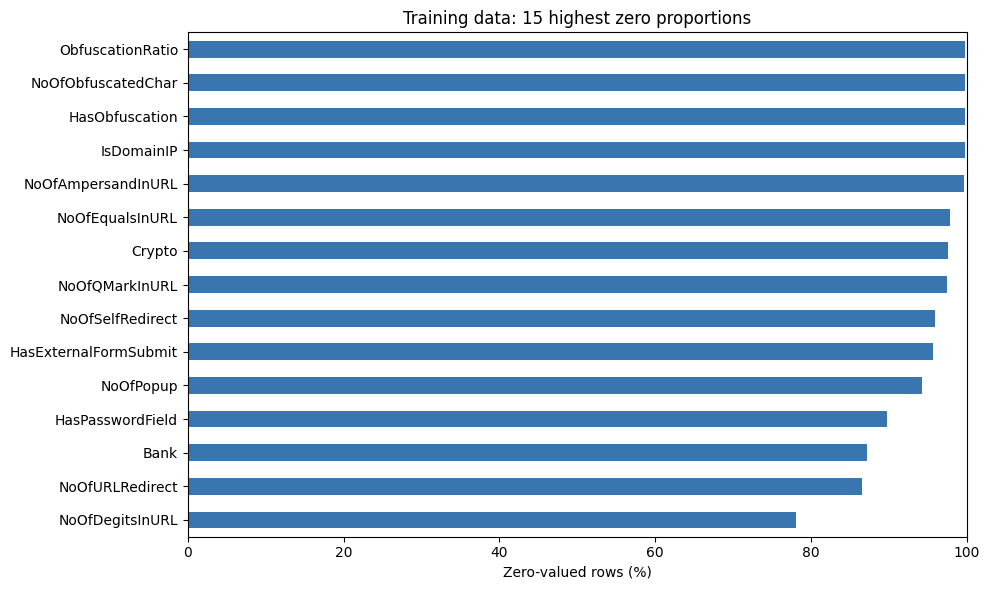

In [9]:
zero_rank = stats[['observed_type','zero_percent','unique']].sort_values('zero_percent',ascending=False)
display(zero_rank.head(15).round(3))
fig,ax = plt.subplots(figsize=(10,6))
zero_rank.head(15)['zero_percent'].sort_values().plot.barh(ax=ax,color='#3976af')
ax.set(title='Training data: 15 highest zero proportions',xlabel='Zero-valued rows (%)',xlim=(0,100))
fig.tight_layout()
fig.savefig(FIGURES/'07_zero_proportions.png',dpi=140)
plt.show(); plt.close(fig)

### 7.2. İkili göstergeler

**Soru:** 0/1 alanlarında iki değer ne kadar sık görülüyor?
Sütun adları gösterge gibi görünse de 0/1 anlamının kaynak tanımıyla doğrulanması gerekir.
Özellikle `NoOfURLRedirect` ve `NoOfSelfRedirect` gibi sayım isimli alanların yalnızca
iki değer alması, veri üretim kuralını sorgulamamızı sağlar; otomatik yeniden adlandırmayız.

,zero_rows,one_rows,one_percent
HasObfuscation,140933,321,0.227
IsDomainIP,140901,353,0.250
Crypto,137921,3333,2.360
NoOfSelfRedirect,135477,5777,4.090
HasExternalFormSubmit,135072,6182,4.377
HasPasswordField,126709,14545,10.297
Bank,123180,18074,12.795
NoOfURLRedirect,122323,18931,13.402
Pay,107777,33477,23.700
Robots,103521,37733,26.713


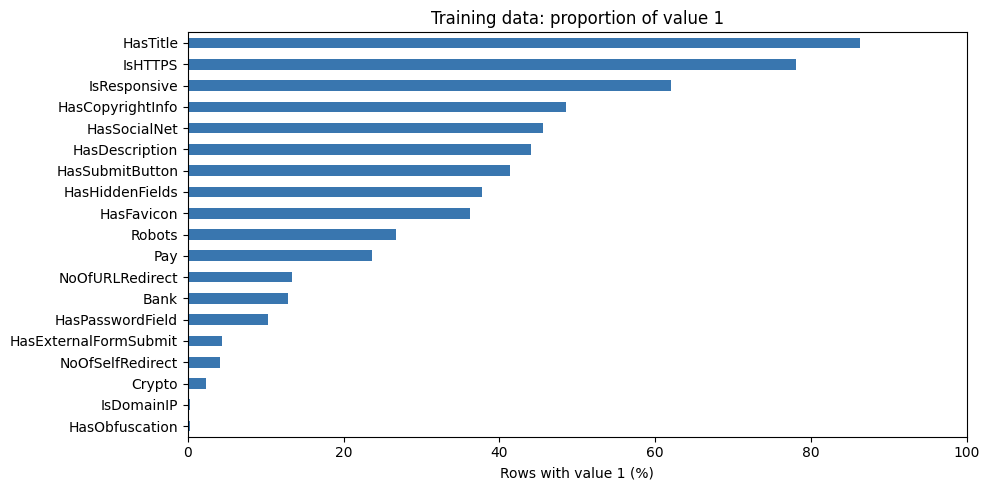

In [10]:
binary_summary = pd.DataFrame({'zero_rows':train[binary_cols].eq(0).sum(),
 'one_rows':train[binary_cols].eq(1).sum(), 'one_percent':train[binary_cols].eq(1).mean()*100})
binary_summary=binary_summary.sort_values('one_percent')
binary_summary.to_csv(DIST/'binary_summary.csv',index_label='feature')
display(binary_summary.round(3))
fig,ax=plt.subplots(figsize=(10,max(5,len(binary_cols)*.24)))
binary_summary.one_percent.plot.barh(ax=ax,color='#3976af')
ax.set(title='Training data: proportion of value 1',xlabel='Rows with value 1 (%)',xlim=(0,100))
fig.tight_layout(); fig.savefig(FIGURES/'07_binary_proportions.png',dpi=140)
plt.show(); plt.close(fig)

### 7.3. Sayısal dağılımların görünümü

Her ikili olmayan, sabit olmayan sayısal özellik gösterilir. Sağ kuyruğun görünmesini
kolaylaştırmak için grafiklerde `log1p(x)` kullanılır; eksendeki değerler dönüştürülmüş
ölçektedir. Bu yalnızca çizim kopyasıdır, eğitim tablosuna dönüşüm uygulanmaz.
Tüm kayıtlar kullanılır; kuyruk kesilmez. Histogramın kutu sayısı 40'tır.
İlk üç örnekte ham ve log görünüm yan yana karşılaştırılır.

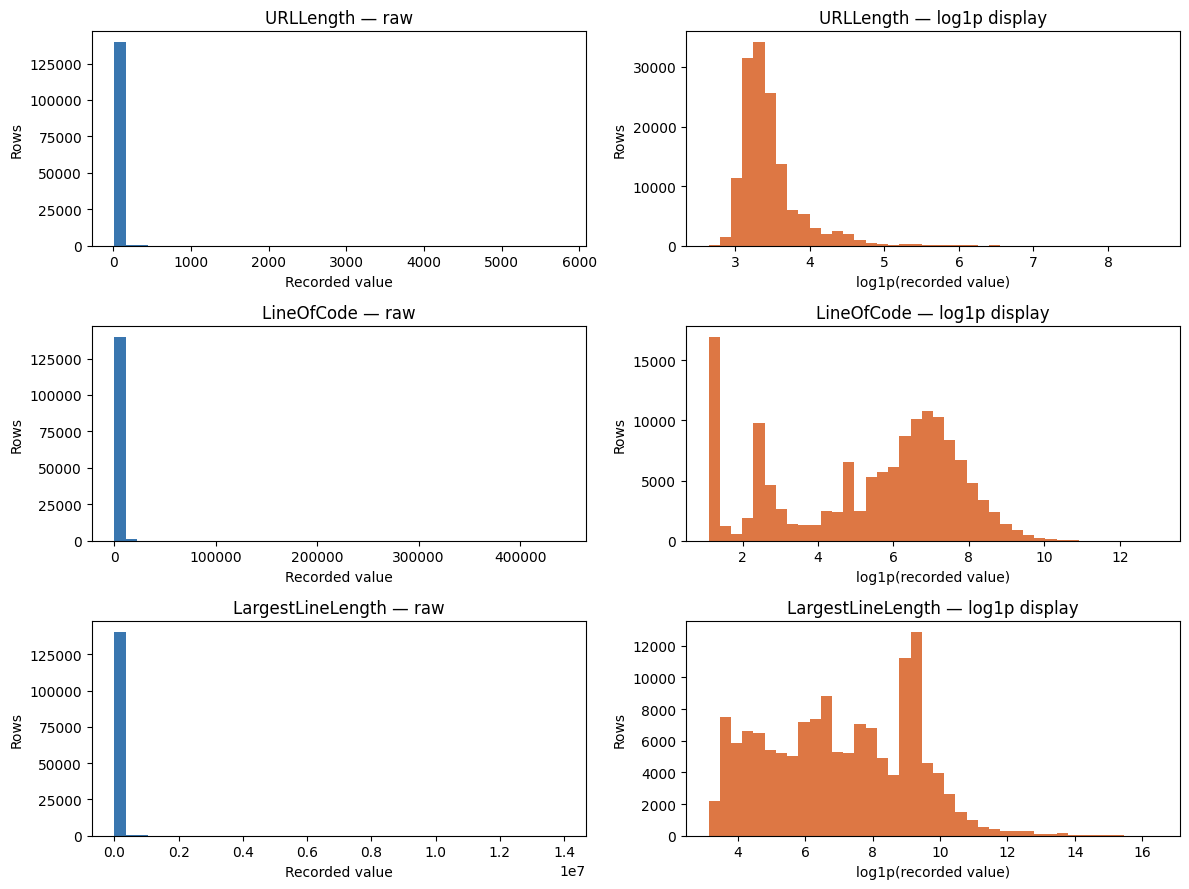

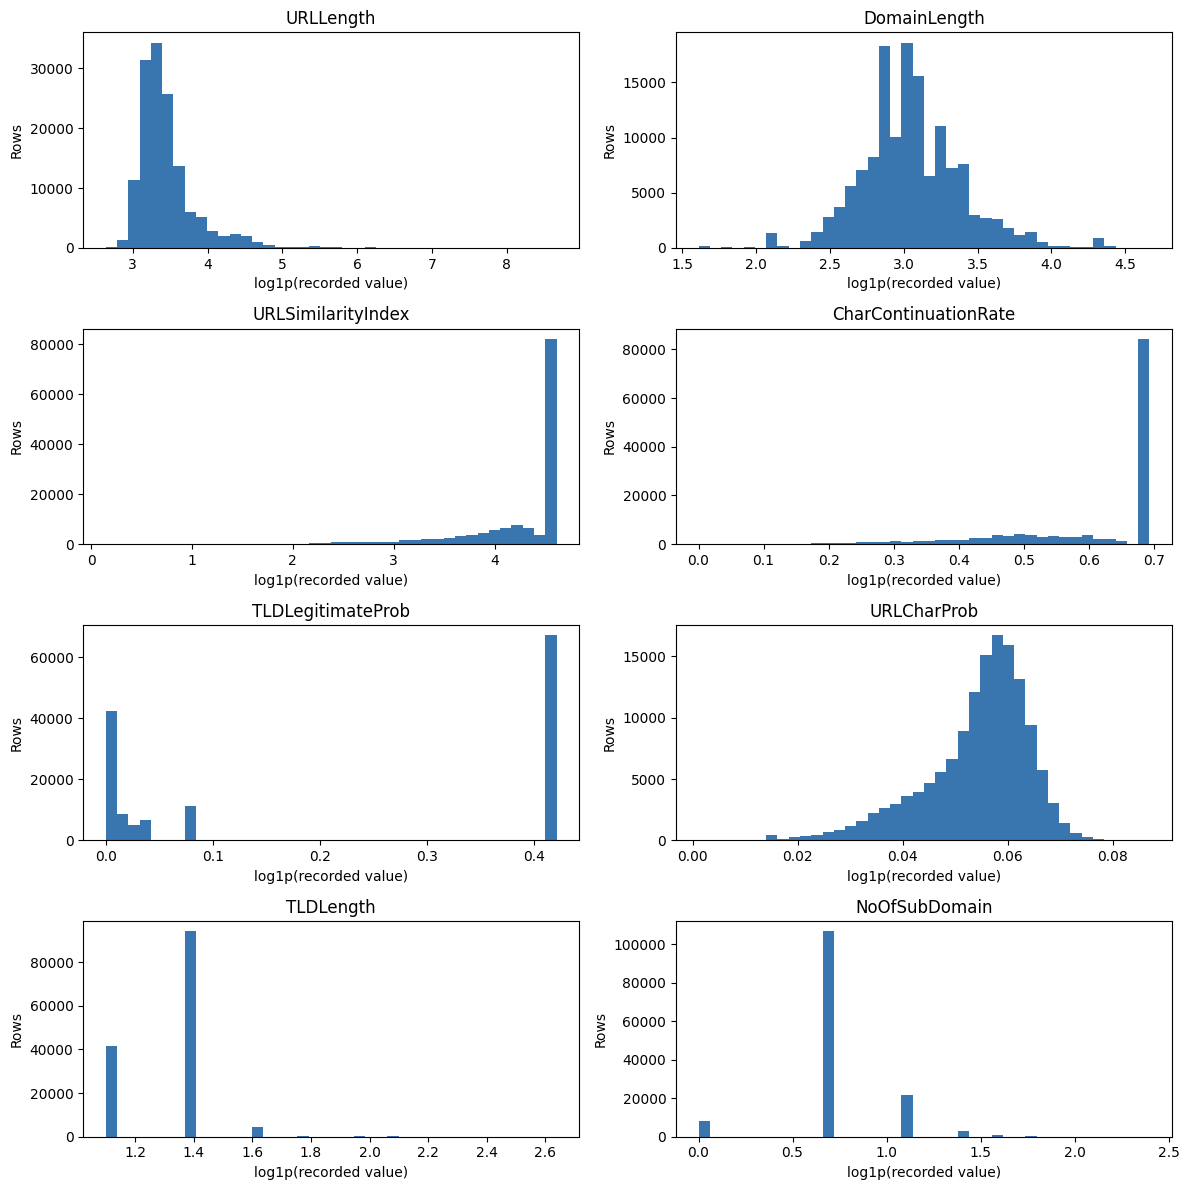

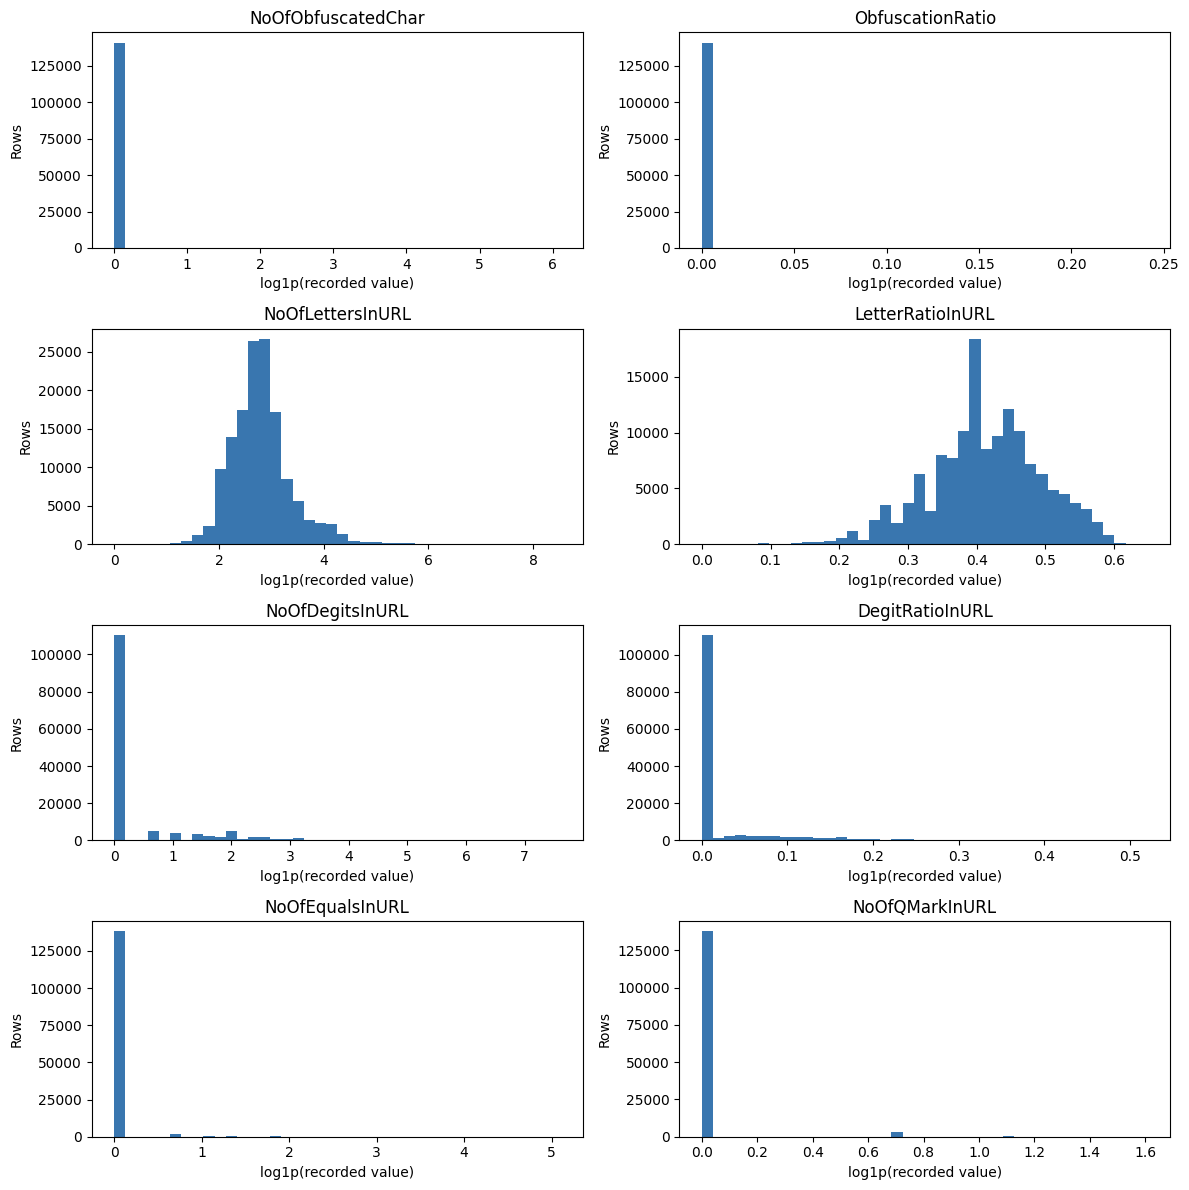

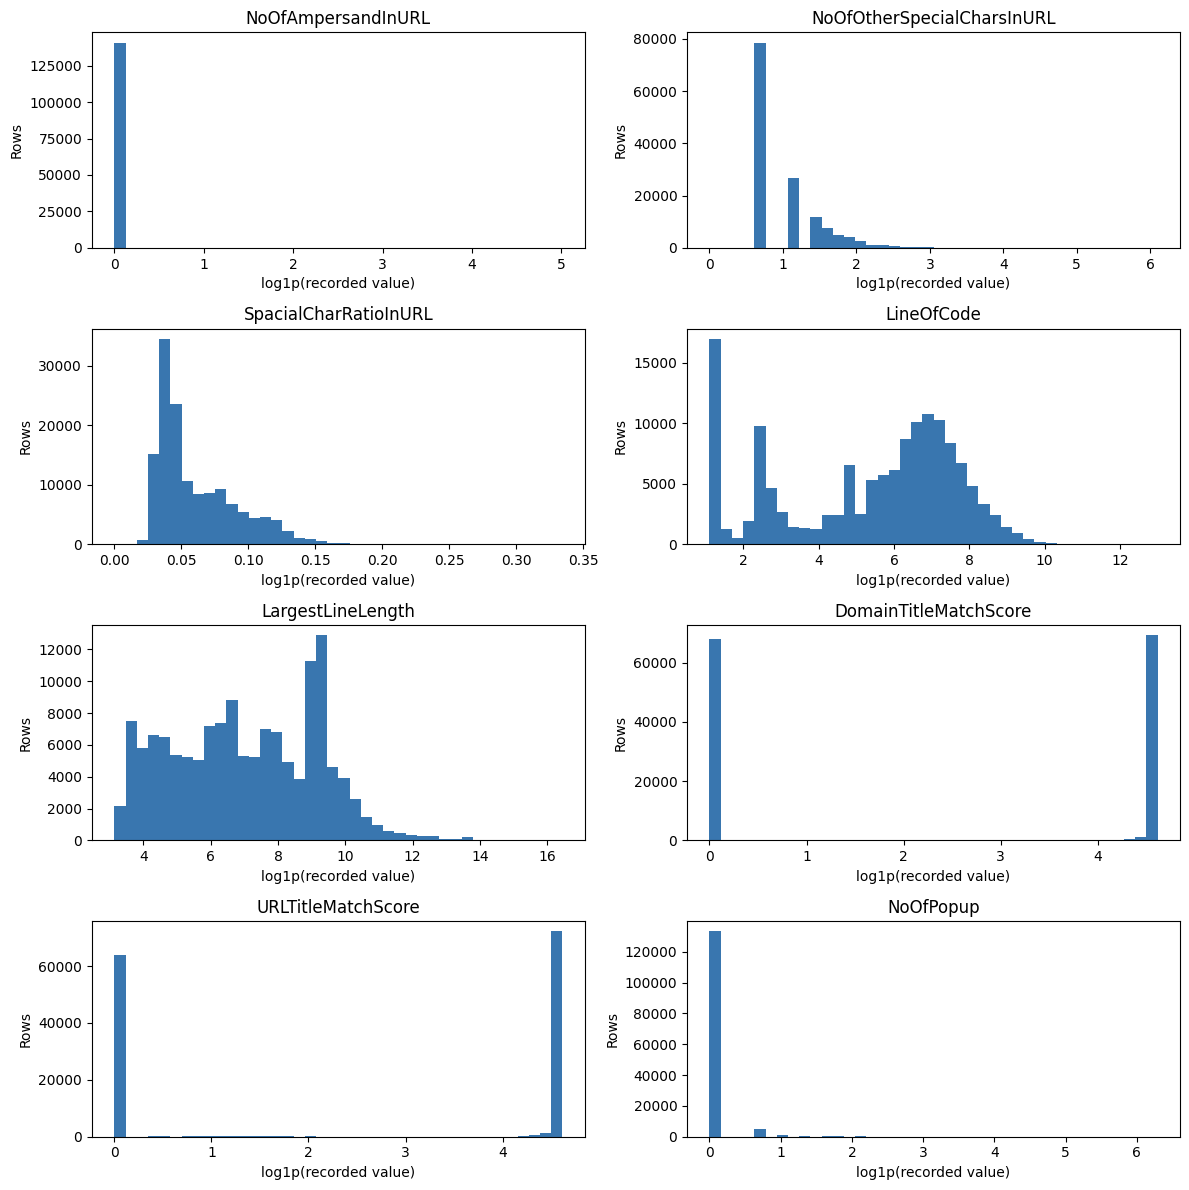

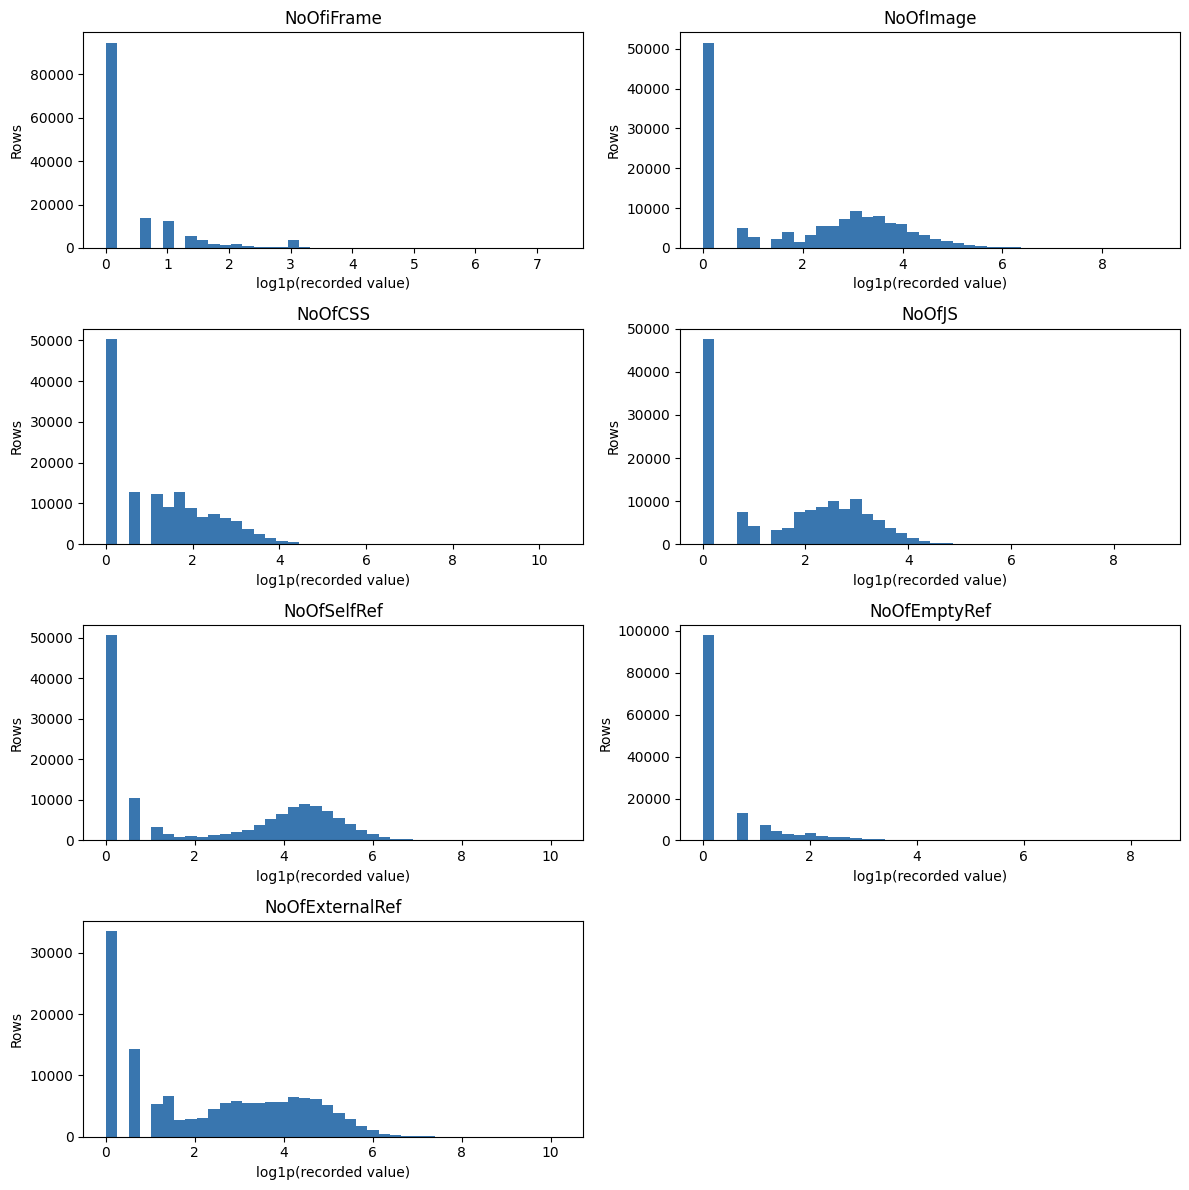

In [11]:
examples = [c for c in ['URLLength','LineOfCode','LargestLineLength'] if c in other_numeric]
fig,axes = plt.subplots(len(examples),2,figsize=(12,3*len(examples)),squeeze=False)
for row,c in enumerate(examples):
    x=train[c].dropna()
    axes[row,0].hist(x,bins=40,color='#3976af')
    axes[row,0].set(title=c+' — raw',xlabel='Recorded value',ylabel='Rows')
    axes[row,1].hist(np.log1p(x),bins=40,color='#dd7744')
    axes[row,1].set(title=c+' — log1p display',xlabel='log1p(recorded value)',ylabel='Rows')
fig.tight_layout(); fig.savefig(FIGURES/'07_raw_and_log_examples.png',dpi=140)
plt.show(); plt.close(fig)
for offset in range(0,len(other_numeric),8):
    columns=other_numeric[offset:offset+8]
    fig,axes=plt.subplots((len(columns)+1)//2,2,figsize=(12,3*((len(columns)+1)//2)),squeeze=False)
    for ax,c in zip(axes.flat,columns):
        values=train[c].dropna()
        if values.ge(0).all():
            values=np.log1p(values); xlabel='log1p(recorded value)'
        else: xlabel='Recorded value (negative values present)'
        ax.hist(values,bins=40,color='#3976af')
        ax.set(title=c,xlabel=xlabel,ylabel='Rows')
    for ax in list(axes.flat)[len(columns):]: ax.set_visible(False)
    fig.tight_layout(); fig.savefig(FIGURES/f'07_numeric_distributions_{offset//8+1:02d}.png',dpi=140)
    plt.show(); plt.close(fig)

### 7.4. Kategorik sıklıklar ve ham metin alanları

**Soru:** Uzantılar hangi kategorilerde yoğunlaşıyor? Kimlik/metin alanlarında benzersizlik
ve uzunluk yapısı nasıl? FILENAME izlenebilirlik, URL/Domain grup bağımlılığı için önemlidir;
bunları sıradan kategori kodlarıyla model girdisine dönüştürmüyoruz.
Başlıkların gerçek metnini veya ham adresleri raporda yayımlamıyoruz.
Kategori çeşitliliği tek başına o kategorinin yararlı olduğunu göstermez.

,unique,unique_percent,rows_in_repeated_values_percent
FILENAME,141254,100.000,0.000
URL,141001,99.821,0.358
Domain,132052,93.485,8.803
TLD,594,0.421,99.899
Title,119428,84.548,17.005


,rows,percent
TLD,,
com,67324,47.662
org,11228,7.949
net,4312,3.053
app,3911,2.769
uk,3778,2.675
co,3430,2.428
io,3070,2.173
de,2373,1.680
ru,2179,1.543


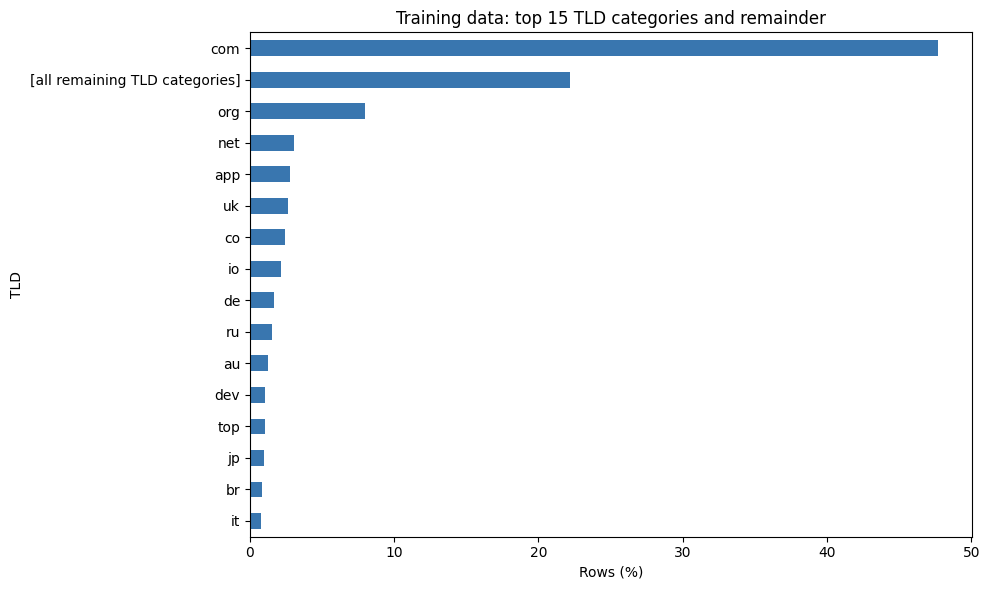

,count,mean,std,min,50%,95%,99%,max
URL,141254.0,35.359,41.496,14.0,28.0,74.0,133.0,5795.0
Domain,141254.0,21.473,9.166,4.0,20.0,38.0,57.0,105.0
Title,141254.0,15.999,33.533,1.0,11.0,44.0,96.47,4118.0


**Dikkat:** Buradaki metin uzunlukları mevcut metinden hesaplanır; kaynak `URLLength` ile aynı tanımda oldukları varsayılmaz. Önceki tutarlılık bulguları geçerlidir.

In [12]:
text_cols = train.select_dtypes(exclude='number').columns.tolist()
text_summary = pd.DataFrame({'unique':train[text_cols].nunique(),
    'unique_percent':train[text_cols].nunique()/len(train)*100,
    'rows_in_repeated_values_percent':[train[c].duplicated(keep=False).mean()*100 for c in text_cols]})
text_summary.to_csv(DIST/'text_summary.csv',index_label='column')
display(text_summary.round(3))
tld_counts=train.TLD.value_counts(dropna=False)
tld_table=tld_counts.rename_axis('TLD').to_frame('rows')
tld_table['percent']=tld_table.rows/len(train)*100
tld_table.to_csv(DIST/'tld_frequencies.csv')
display(tld_table.head(15).round(3))
top_tld=tld_counts.head(15).copy()
remaining=int(tld_counts.iloc[15:].sum())
if remaining: top_tld.loc['[all remaining TLD categories]']=remaining
fig,ax=plt.subplots(figsize=(10,6))
(top_tld/len(train)*100).sort_values().plot.barh(ax=ax,color='#3976af')
ax.set(title='Training data: top 15 TLD categories and remainder',xlabel='Rows (%)')
fig.tight_layout(); fig.savefig(FIGURES/'07_tld_frequencies.png',dpi=140)
plt.show(); plt.close(fig)
text_lengths=pd.DataFrame({c:train[c].astype('string').str.len() for c in ['URL','Domain','Title']})
display(text_lengths.describe(percentiles=[.5,.95,.99]).T.round(3))
text_lengths.describe(percentiles=[.5,.95,.99]).T.to_csv(DIST/'text_length_summary.csv',index_label='column')
display(Markdown('**Dikkat:** Buradaki metin uzunlukları mevcut metinden hesaplanır; kaynak `URLLength` ile aynı tanımda oldukları varsayılmaz. Önceki tutarlılık bulguları geçerlidir.'))

### 7.5. Bulgular ve 12. bölüm için inceleme notları

Aşağıdaki özet ölçülmüş sonuçlardan üretilir. Yüksek sıfır oranı veya çarpıklık,
özellik silme ya da dönüşüm uygulama kararı değildir. Sonraki bölümde uç kayıtlar
ve mantıksal geçerlilik daha ayrıntılı incelenecek.

In [13]:
distribution_findings = {
    'training_rows':len(train),'numeric_predictor_candidates':len(numeric_cols),
    'constant_numeric_columns':constant_cols,'binary_numeric_columns':binary_cols,
    'columns_at_least_95_percent_zero':stats.index[stats.zero_percent.ge(95)].tolist(),
    'tld_unique':int(train.TLD.nunique()),
    'tld_top_15_row_percent':float(tld_counts.head(15).sum()/len(train)*100),
    'policy':'Training descriptive analysis only; no cleaning or feature selection.'}
(DIST/'findings.json').write_text(json.dumps(distribution_findings,indent=2),encoding='utf-8')
display(Markdown(f"**Bulgu:** {len(numeric_cols)} sayısal özellik adayı; {len(binary_cols)} ikili alan; {len(constant_cols)} sabit alan. En az %95 sıfır içeren {int(stats.zero_percent.ge(95).sum())} alan var. Eğitimde {train.TLD.nunique()} farklı TLD bulunuyor; ilk 15 kategori kayıtların %{tld_counts.head(15).sum()/len(train)*100:.2f}'sini kapsıyor."))
print('Üst kuyruğu belirgin alanlar (çarpıklığa göre ilk 10; hata etiketi değildir):')
display(stats.loc[other_numeric,['50%','95%','99%','max','zero_percent','skewness']].sort_values('skewness',ascending=False).head(10).round(3))
assert before_distribution_hash == hashlib.sha256(pd.util.hash_pandas_object(train,index=True).values.tobytes()).hexdigest()
display(Markdown('**Karar:** Eğitim tablosunun değişmediği doğrulandı. Sıfır ağırlıklı alanların anlamı, sayım isimli ikili alanlar ve uzun kuyruklar 8–11. bölümlerde incelenecek; uygulanacak veri hazırlama akışı 12. bölümde belirlenecek.'))

**Bulgu:** 50 sayısal özellik adayı; 19 ikili alan; 0 sabit alan. En az %95 sıfır içeren 10 alan var. Eğitimde 594 farklı TLD bulunuyor; ilk 15 kategori kayıtların %77.79'sini kapsıyor.

Üst kuyruğu belirgin alanlar (çarpıklığa göre ilk 10; hata etiketi değildir):


,50%,95%,99%,max,zero_percent,skewness
NoOfCSS,2.0,26.0,52.0,35820.0,35.672,365.018
NoOfObfuscatedChar,0.0,0.0,0.0,447.0,99.773,197.726
NoOfJS,6.0,38.0,64.0,6957.0,33.751,149.768
NoOfAmpersandInURL,0.0,0.0,0.0,149.0,99.620,123.834
NoOfEmptyRef,0.0,10.0,31.0,4887.0,69.301,123.140
NoOfiFrame,0.0,8.0,21.0,1602.0,66.947,114.915
NoOfEqualsInURL,0.0,0.0,1.0,163.0,97.817,109.809
NoOfDegitsInURL,0.0,10.0,28.0,2011.0,78.129,93.295
NoOfPopup,0.0,1.0,4.0,540.0,94.283,74.261
NoOfExternalRef,10.0,208.0,422.0,27516.0,23.723,65.266


**Karar:** Eğitim tablosunun değişmediği doğrulandı. Sıfır ağırlıklı alanların anlamı, sayım isimli ikili alanlar ve uzun kuyruklar 8–11. bölümlerde incelenecek; uygulanacak veri hazırlama akışı 12. bölümde belirlenecek.

### 7.6. Bulguların değerlendirilmesi

Bu bulgular yalnızca **141.254 eğitim kaydına** aittir. Hedefe göre karşılaştırma
yapılmadığından, hangi özelliğin phishing tespitinde yararlı olduğunu henüz söylemez.

**1. Sayısal alanlarda çeşitlilik var; sabit sütun yok.** Hedef dışındaki 50
sayısal alanın 19'u yalnızca 0/1 değerleri alıyor, 31'i diğer sayısal alanlardan
oluşuyor. Sabitlik nedeniyle şu aşamada elenecek bir sayısal sütun görülmedi.
Bu, alanların birbirinden bağımsız veya tahminde yararlı olduğu anlamına gelmez.

**2. Bazı özellikler çok seyrek görülüyor.** 10 sütunun en az %95'i sıfır.
Örneğin `HasObfuscation` yalnızca 321 kayıtta (%0,227), `IsDomainIP` 353 kayıtta
(%0,250) 1 değerini alıyor. `NoOfObfuscatedChar` ve `ObfuscationRatio` alanlarının
da %99,773'ü sıfır. Bu durum nadir gözlemler olduğunu gösterir; sıfırların
özellik yokluğu mu yoksa çıkarım davranışı mı olduğu ayrıca incelenmeli.
Seyrek oldukları için bu alanları otomatik olarak silmeyeceğiz.

**3. Bazı sayısal dağılımların sağ kuyruğu çok uzun.**

| Özellik | Medyan | %99 yüzdelik | Maksimum |
|---|---:|---:|---:|
| URLLength | 27 | 133 | 5.794 |
| LineOfCode | 429 | 10.307,47 | 442.666 |
| LargestLineLength | 1.067 | 143.897 | 13.975.732 |

Maksimumlar tipik gözlemlerden çok uzak. Ham histogramlarda uç değerler yatay
ekseni genişlettiği için kayıtların çoğu dar bir bölgede sıkışıyor. `log1p`
görünümü bu yapıyı okunabilir hale getiriyor; uç değerlerin hatalı olduğunu
kanıtlamıyor. `URLLength` hakkındaki önceki tutarlılık sorunu da devam ediyor.
8. bölümde uç kayıtları incelemeden kırpma veya silme kararı vermeyeceğiz.

**4. İkili alanların görülme oranları birbirinden farklı.** `HasTitle` %86,303,
kayıtlı `IsHTTPS` %78,128 ve `IsResponsive` %62,071 oranında 1 değerini alıyor.
Bu oranlar tüm eğitim örneklemini tanımlar; meşru ve phishing sınıfları arasında
ayrım gücünü göstermez. Ayrıca `IsHTTPS` için daha önce bulunan tanım/uyum
sorunu nedeniyle bu oranı doğrudan doğrulanmış HTTPS kullanım oranı diye sunmuyoruz.

**5. Sayım isimli bazı alanlar yalnızca iki değer alıyor.** `NoOfURLRedirect`
ve `NoOfSelfRedirect` eğitimde yalnızca 0/1 içeriyor. Kaynak süreç sayıyı
sınırlandırmış veya varlık göstergesi üretmiş olabilir; yalnızca bu gözlemden
özgün tanımı değiştiremeyiz. Çıkarım kuralı doğrulanacak.

**6. TLD dağılımı birkaç kategoride yoğunlaşıyor.** 594 farklı uzantı bulunuyor.
`com` tek başına %47,662, `org` %7,949 ve `net` %3,053 paya sahip.
İlk 15 kategori kayıtların %77,790'ını kapsıyor; kalan yüzlerce kategori
birlikte yaklaşık %22,210'u oluşturuyor. Bu, kategorik uzun kuyruk olduğunu
gösterir. Nadir kategorilerin nasıl ele alınacağına veya TLD'nin kullanılmasına
henüz karar verilmedi; bu dağılımın gerçek internet trafiğini temsil ettiği
varsayılmamalı.

**7. Kimlik ve metin alanları ayrı amaçlarla ele alınmalı.** Benzersizlik ve
tekrar oranları, FILENAME/URL/Domain/Title gibi alanların sıradan sayısal
özelliklerden farklı olduğunu gösteren envanterdir. URL ve domain tekrarları
bağımlılık kontrolü için, başlık metni ise ancak kapsamı belirlenmiş ayrı bir
metin işleme akışı için değerlendirilir. Bunlar otomatik kategori kodlarıyla
model girdisine çevrilmedi.

**12. bölüme taşınacak notlar:** Seyrek alanların anlamı, uzun kuyrukların
geçerliliği, yönlendirme alanlarının tanımı, TLD'nin nadir kategorileri ve
özelliklerin canlıda üretilebilirliği değerlendirmeye alınacak.
**Bu bölüm sonunda hiçbir sütun/satır silinmedi ve veri dönüşümü uygulanmadı.**


## 8. Aykırı değerler

Uç değerlerin hata mı, makul gözlem mi veya olası saldırı sinyali mi olduğunu değerlendireceğiz. Otomatik silme uygulamayacağız.

## 9. Hedefle ilişkiler

Sınıflara göre özellik dağılımlarını karşılaştıracağız. Etki büyüklüğü, örneklem büyüklüğü ve toplama yanlılığını dikkate alacağız; ilişkiyi nedensellik olarak sunmayacağız.

## 10. Özellikler arası ilişkiler

Korelasyon, türetilmiş alanlar, tekrar eden bilgi ve mantıksal ilişkileri inceleyeceğiz. Yalnızca korelasyona bakarak sütun silmeyeceğiz.

## 11. Veri sızıntısı ve canlı kullanım uyumu

Özelliklerin kaynağını, etiket veya referans veri kullanımını ve tahmin anında erişilebilirliğini sorgulayacağız. HTTPS şeması ile sertifika geçerliliğini ayıracağız.

## 12. Bulgular ve veri hazırlama yol haritası

İncelemeler tamamlandığında karar tablosunu gerçek bulgularla dolduracağız. Temizleme ve özellik mühendisliği akışı bu değerlendirmeden sonra oluşturulacak.

| Bulgu | Kanıt | Önerilen işlem | Gerekçe | Açık soru / doğrulama |
|---|---|---|---|---|